# Studi Kasus 5 — *Human-Computer Interaction & Data Visualization*

**Pemateri:** Dr. Arafat Febriandirza (Ketua Kelompok Riset Interaksi Manusia-Komputer dan Visualisasi, Pusat Riset
Sains Data dan Informasi — BRIN)
**Video:** https://www.youtube.com/live/5KhQm8OaYRM
**Seri:** Informatics Practitioner Lecture Series 2026 — Prodi Informatika Universitas Bengkulu

---

## Ringkasan materi pemateri

1. **IMK** mempelajari jembatan komunikasi manusia ↔ komputer (pilar: *human*, *interaction/interface*, *computer*).
   Evolusi: kartu berlubang → *command line* → GUI → *natural UI* (sentuh, suara, AR/VR). Aturan emas:
   ***you are not your user*** → *user-centered design*.
2. **Aspek kognitif**: persepsi sensori → pemrosesan kognitif → respons motorik; *working memory* ±7±2 item →
   utamakan ***recognition over recall***. Beban kognitif: *intrinsic*, ***extraneous*** (musuh utama — tata letak
   berantakan, warna membingungkan), *germane*. **Atribut pre-atentif** (warna, ukuran, bentuk, orientasi) dikenali
   < 200 ms. **Prinsip Gestalt**: *proximity, similarity, enclosure, continuity, closure, figure-ground*.
3. **Konteks**: fisik (cahaya, ukuran layar), sosial (privasi, hierarki), teknis (internet, perangkat). Pengguna beragam
   (lansia, profesional, Gen-Z) → aksesibilitas **POUR** (*Perceivable, Operable, Understandable, Robust*).
   **Etika**: hindari *dark pattern*, sajikan grafik **jujur** tanpa distorsi skala.
4. **Proses desain iteratif**: analisis → desain → *prototype* (*low-fi* → *high-fi*, *fail early fail cheap*) →
   evaluasi (**evaluasi heuristik 10 prinsip Nielsen** & **usability testing**). Prinsip dasar: *visibility, feedback,
   constraint, consistency, affordance*.
5. **Kebutuhan** fungsional vs non-fungsional (mis. grafik dimuat < 2 detik, kontras memenuhi standar);
   **persona** (demografi, *goals*, *pain points*, perilaku) & **skenario** (konteks → *trigger* → aksi → hasil).
   Contoh persona: **Budi, data analyst 30 th** — *"Saya butuh melihat tren ringkas dalam 5 detik sebelum rapat."*
6. **Visualisasi data**: tujuan eksplorasi–komunikasi–konfirmasi; pilih grafik sesuai tugas (garis = tren waktu,
   batang = perbandingan kategori, *scatter* = korelasi, pie = proporsi saja); hindari ***chartjunk***, maksimalkan
   ***data-ink ratio*** (Tufte); **mantra Shneiderman**: *overview first, zoom and filter, then details on demand*.
7. Tanya-jawab: indikator objektif *usability* → 10 heuristik Nielsen, tingkat keberhasilan tugas; keterampilan paling
   mendasar → **analisis kebutuhan pengguna**; AI adalah "staf/agen" yang mempercepat, bukan pengganti empati desainer.

## Latar belakang studi kasus

Dinas Koperasi & UMKM (fiktif) memiliki *dashboard* penjualan UMKM Provinsi Bengkulu yang lama: lambat, penuh angka,
grafik 3D, dan warna pelangi. Analis data seperti **persona Budi** mengeluh tidak bisa menangkap tren sebelum rapat.
Kita merancang ulang *dashboard* mengikuti **siklus desain interaksi** dan **membuktikan** perbaikannya dengan metrik
*usability* yang objektif.

## Tujuan
1. Menerjemahkan persona & skenario menjadi kebutuhan fungsional/non-fungsional yang dapat diuji.
2. Menerapkan prinsip visualisasi: pemilihan grafik, *data-ink ratio*, atribut pre-atentif, Gestalt, skala jujur.
3. Memeriksa aksesibilitas (rasio kontras WCAG, simulasi buta warna).
4. Membangun *dashboard* interaktif sesuai mantra Shneiderman.
5. Mengevaluasi: evaluasi heuristik Nielsen + *usability testing* (tingkat keberhasilan, waktu tugas, SUS).

## 0. Persiapan

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats

rng = np.random.default_rng(11)
plt.rcParams.update({"figure.dpi": 100})

## 1. Analisis: persona, skenario, dan kebutuhan

In [2]:
persona = {
    "nama": "Budi Pratama", "usia": 30, "pekerjaan": "Data analyst, Dinas Koperasi & UMKM Prov. Bengkulu",
    "kutipan": "Saya butuh melihat tren ringkas dalam 5 detik sebelum rapat eksekutif.",
    "goals": ["memantau KPI penjualan UMKM harian", "menemukan kabupaten/sektor yang turun", "membagikan grafik ke layar rapat"],
    "pain_points": ["dashboard lama lambat dimuat", "terlalu banyak angka tanpa pembeda warna", "grafik 3D sulit dibaca"],
    "perilaku": ["memakai tablet saat rapat", "membuka dashboard 5–10 kali sehari", "sering di ruangan terang"],
}
skenario = {"konteks": "Rapat pagi mendadak bersama Kepala Dinas",
            "trigger": "Kepala Dinas bertanya: 'Kabupaten mana yang penjualannya turun bulan ini?'",
            "aksi": "Budi membuka dashboard di tablet, memfilter bulan terakhir, menyorot kabupaten yang turun",
            "hasil": "Jawaban ditemukan < 10 detik dan grafiknya ditampilkan ke layar besar"}
kebutuhan = pd.DataFrame([
    ("F1", "Fungsional", "Menampilkan ringkasan KPI (total penjualan, pertumbuhan, jumlah UMKM aktif)"),
    ("F2", "Fungsional", "Filter rentang tanggal dan kabupaten/kota"),
    ("F3", "Fungsional", "Detail angka muncul saat hover/klik (details on demand)"),
    ("F4", "Fungsional", "Ekspor grafik (PNG/HTML) untuk dibagikan"),
    ("N1", "Non-fungsional", "Waktu render grafik < 2 detik"),
    ("N2", "Non-fungsional", "Rasio kontras teks ≥ 4,5:1 (WCAG AA)"),
    ("N3", "Non-fungsional", "Warna tetap dapat dibedakan oleh pengguna buta warna"),
    ("N4", "Non-fungsional", "Maksimal 5–7 elemen informasi utama per layar (batas working memory)"),
], columns=["kode", "jenis", "kebutuhan"])
print(f"PERSONA: {persona['nama']} — \"{persona['kutipan']}\"")
print("SKENARIO:", " → ".join(skenario.values()))
kebutuhan

PERSONA: Budi Pratama — "Saya butuh melihat tren ringkas dalam 5 detik sebelum rapat eksekutif."
SKENARIO: Rapat pagi mendadak bersama Kepala Dinas → Kepala Dinas bertanya: 'Kabupaten mana yang penjualannya turun bulan ini?' → Budi membuka dashboard di tablet, memfilter bulan terakhir, menyorot kabupaten yang turun → Jawaban ditemukan < 10 detik dan grafiknya ditampilkan ke layar besar


,kode,jenis,kebutuhan
0,F1,Fungsional,"Menampilkan ringkasan KPI (total penjualan, pe..."
1,F2,Fungsional,Filter rentang tanggal dan kabupaten/kota
2,F3,Fungsional,Detail angka muncul saat hover/klik (details o...
3,F4,Fungsional,Ekspor grafik (PNG/HTML) untuk dibagikan
4,N1,Non-fungsional,Waktu render grafik < 2 detik
5,N2,Non-fungsional,"Rasio kontras teks ≥ 4,5:1 (WCAG AA)"
6,N3,Non-fungsional,Warna tetap dapat dibedakan oleh pengguna buta...
7,N4,Non-fungsional,Maksimal 5–7 elemen informasi utama per layar ...


## 2. Data penjualan UMKM (sintetis)

In [3]:
kab = ["Kota Bengkulu", "Bengkulu Utara", "Rejang Lebong", "Seluma", "Kepahiang", "Mukomuko", "Kaur",
       "Bengkulu Selatan", "Lebong", "Bengkulu Tengah"]
sektor = ["Kuliner", "Fesyen", "Kerajinan", "Pertanian Olahan", "Jasa"]
tgl = pd.date_range("2025-01-01", "2026-09-30", freq="D")
basis = dict(zip(kab, [40, 18, 22, 10, 9, 8, 6, 11, 5, 7]))
baris = []
for k in kab:
    for s_i, s in enumerate(sektor):
        tren = np.linspace(1, 1.35, len(tgl))
        if k == "Seluma":  # anomali: penjualan Seluma turun tajam 3 bulan terakhir
            tren = np.where(tgl >= "2026-07-01", tren * 0.6, tren)
        musim = 1 + 0.25 * np.isin(tgl.month, [3, 4]) + 0.1 * (tgl.dayofweek >= 5)   # efek Ramadan/Lebaran & akhir pekan
        nilai = basis[k] * [1.4, 0.9, 0.5, 0.8, 0.7][s_i] * tren * musim * rng.lognormal(0, 0.15, len(tgl))
        baris.append(pd.DataFrame({"tanggal": tgl, "kabupaten": k, "sektor": s, "penjualan_juta": nilai.round(2)}))
jual = pd.concat(baris, ignore_index=True)
jual["bulan"] = jual.tanggal.dt.to_period("M").dt.to_timestamp()
print(jual.shape); jual.head()

(31900, 5)


,tanggal,kabupaten,sektor,penjualan_juta,bulan
0,2025-01-01,Kota Bengkulu,Kuliner,56.29,2025-01-01
1,2025-01-02,Kota Bengkulu,Kuliner,68.71,2025-01-01
2,2025-01-03,Kota Bengkulu,Kuliner,67.37,2025-01-01
3,2025-01-04,Kota Bengkulu,Kuliner,57.15,2025-01-01
4,2025-01-05,Kota Bengkulu,Kuliner,59.04,2025-01-01


## 3. Prinsip visualisasi: sebelum vs sesudah

### 3.1 Memilih grafik yang tepat & menghindari *chartjunk*
**Sebelum:** pie 10 irisan + warna pelangi + bayangan/"3D". **Sesudah:** batang horizontal terurut, satu warna,
label langsung (data-ink ratio tinggi).

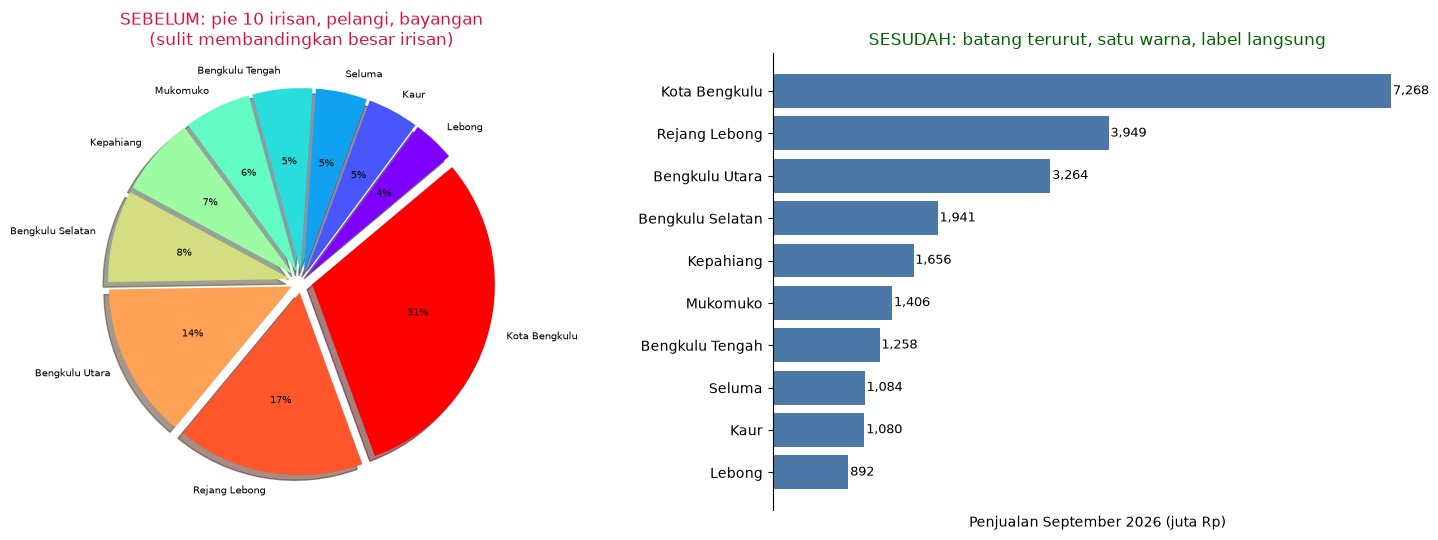

In [4]:
per_kab = jual[jual.bulan == "2026-09-01"].groupby("kabupaten").penjualan_juta.sum().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].pie(per_kab, labels=per_kab.index, colors=plt.cm.rainbow(np.linspace(0, 1, len(per_kab))),
          shadow=True, explode=[0.06] * len(per_kab), startangle=40, autopct="%1.0f%%", textprops={"fontsize": 7})
ax[0].set_title("SEBELUM: pie 10 irisan, pelangi, bayangan\n(sulit membandingkan besar irisan)", color="crimson")
ax[1].barh(per_kab.index, per_kab.values, color="#4C78A8")
for y, v in enumerate(per_kab.values):
    ax[1].text(v + 20, y, f"{v:,.0f}", va="center", fontsize=9)
ax[1].set_title("SESUDAH: batang terurut, satu warna, label langsung", color="darkgreen")
ax[1].spines[["top", "right", "bottom"]].set_visible(False); ax[1].set_xticks([])
ax[1].set_xlabel("Penjualan September 2026 (juta Rp)")
plt.tight_layout(); plt.show()

### 3.2 Atribut pre-atentif: sorot yang penting saja
Mata menangkap warna mencolok < 200 ms. Gunakan **satu** warna tegas hanya untuk anomali/KPI kritis, sisanya abu-abu.

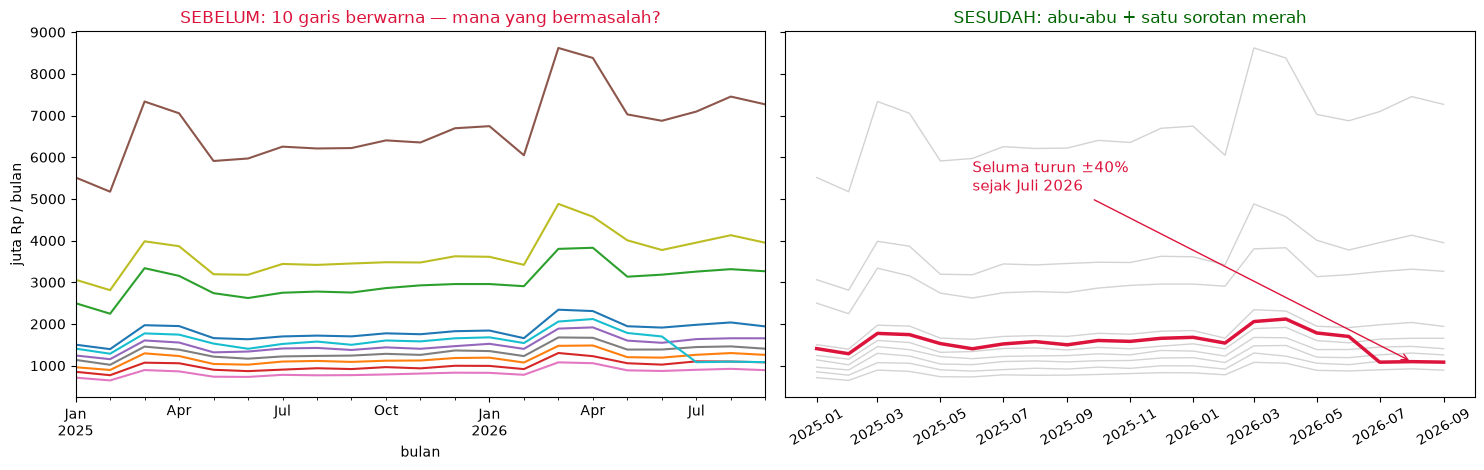

In [5]:
bulanan = jual.groupby(["bulan", "kabupaten"]).penjualan_juta.sum().unstack()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
bulanan.plot(ax=ax[0], legend=False, colormap="tab10")
ax[0].set_title("SEBELUM: 10 garis berwarna — mana yang bermasalah?", color="crimson")
for k in bulanan:
    sorot = k == "Seluma"
    ax[1].plot(bulanan.index, bulanan[k], color="crimson" if sorot else "lightgray", lw=2.5 if sorot else 1)
ax[1].annotate("Seluma turun ±40%\nsejak Juli 2026", xy=(pd.Timestamp("2026-08-01"), bulanan.loc["2026-08-01", "Seluma"]),
               xytext=(pd.Timestamp("2025-06-01"), 5200), color="crimson", fontsize=11,
               arrowprops={"color": "crimson", "arrowstyle": "->"})
ax[1].tick_params(axis="x", labelrotation=30)
ax[1].set_title("SESUDAH: abu-abu + satu sorotan merah", color="darkgreen")
for a in ax: a.set_ylabel("juta Rp / bulan")
plt.tight_layout(); plt.show()

### 3.3 Prinsip Gestalt: *proximity* & *similarity* lewat *small multiples*
Panel kecil yang berdekatan dengan skala & warna sama membuat otak langsung mengelompokkan dan membandingkan pola.

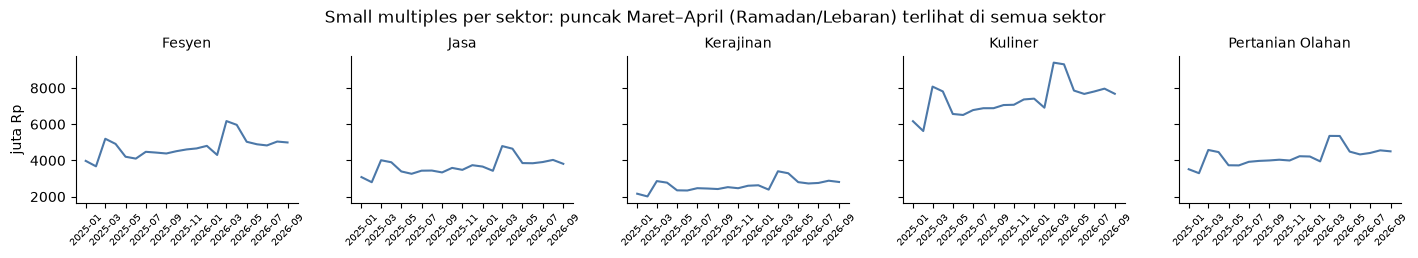

In [6]:
sektor_bln = jual.groupby(["bulan", "sektor"]).penjualan_juta.sum().reset_index()
g = sns.FacetGrid(sektor_bln, col="sektor", col_wrap=5, height=2.4, aspect=1.2, sharey=True)
g.map_dataframe(sns.lineplot, x="bulan", y="penjualan_juta", color="#4C78A8")
g.set_titles("{col_name}"); g.set_axis_labels("", "juta Rp")
for a in g.axes: a.tick_params(axis="x", labelrotation=45, labelsize=7)
g.fig.suptitle("Small multiples per sektor: puncak Maret–April (Ramadan/Lebaran) terlihat di semua sektor", y=1.05)
plt.show()

### 3.4 Etika: skala yang jujur (*lie factor* Tufte)
Memotong sumbu-y membuat kenaikan kecil terlihat dramatis — termasuk *dark pattern* dalam visualisasi.

$\text{Lie factor} = \dfrac{\text{besar efek pada grafik}}{\text{besar efek pada data}}$ (ideal ≈ 1).

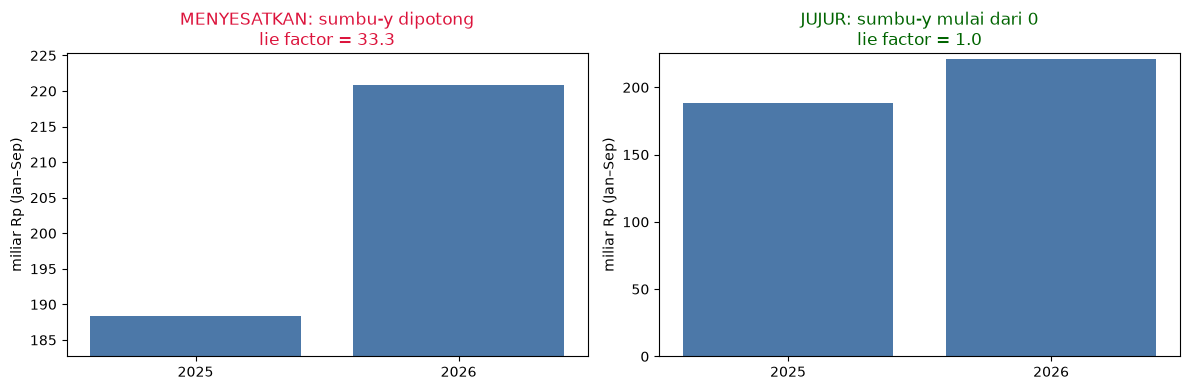

In [7]:
dua = jual[jual.tanggal.dt.year.isin([2025, 2026]) & jual.tanggal.dt.month.isin(range(1, 10))]
tahunan = dua.groupby(dua.tanggal.dt.year).penjualan_juta.sum() / 1000
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, ymin, judul, warna in [(ax[0], tahunan.min() * 0.97, "MENYESATKAN: sumbu-y dipotong", "crimson"),
                              (ax[1], 0, "JUJUR: sumbu-y mulai dari 0", "darkgreen")]:
    a.bar(tahunan.index.astype(str), tahunan.values, color="#4C78A8"); a.set_ylim(ymin, tahunan.max() * 1.02)
    efek_data = tahunan.iloc[1] / tahunan.iloc[0] - 1
    efek_grafik = (tahunan.iloc[1] - ymin) / (tahunan.iloc[0] - ymin) - 1
    a.set_title(f"{judul}\nlie factor = {efek_grafik / efek_data:.1f}", color=warna); a.set_ylabel("miliar Rp (Jan–Sep)")
plt.tight_layout(); plt.show()

## 4. Aksesibilitas (POUR — *Perceivable*)

### 4.1 Rasio kontras WCAG 2.x
$\text{rasio} = \dfrac{L_1 + 0{,}05}{L_2 + 0{,}05}$ dengan $L$ = *relative luminance*. Teks normal wajib ≥ 4,5:1 (AA).

In [8]:
def luminansi(hexwarna):
    c = np.array(mcolors.to_rgb(hexwarna))
    c = np.where(c <= 0.03928, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
    return 0.2126 * c[0] + 0.7152 * c[1] + 0.0722 * c[2]

def rasio_kontras(a, b):
    la, lb = sorted([luminansi(a), luminansi(b)], reverse=True)
    return (la + 0.05) / (lb + 0.05)

pasangan = [("#FFFF00", "#FFFFFF", "kuning di atas putih (dashboard lama)"),
            ("#999999", "#FFFFFF", "abu-abu muda di atas putih (dashboard lama)"),
            ("#4C78A8", "#FFFFFF", "biru aksen di atas putih"),
            ("#333333", "#FFFFFF", "teks gelap di atas putih (baru)"),
            ("#FFFFFF", "#B22222", "putih di atas merah sorotan (baru)")]
cek = pd.DataFrame([(d, f, b, rasio_kontras(f, b)) for f, b, d in pasangan],
                   columns=["pasangan", "teks", "latar", "rasio"])
cek["WCAG AA (≥4,5)"] = np.where(cek.rasio >= 4.5, "LULUS", "GAGAL")
cek.round(2)

,pasangan,teks,latar,rasio,"WCAG AA (≥4,5)"
0,kuning di atas putih (dashboard lama),#FFFF00,#FFFFFF,1.07,GAGAL
1,abu-abu muda di atas putih (dashboard lama),#999999,#FFFFFF,2.85,GAGAL
2,biru aksen di atas putih,#4C78A8,#FFFFFF,4.61,LULUS
3,teks gelap di atas putih (baru),#333333,#FFFFFF,12.63,LULUS
4,putih di atas merah sorotan (baru),#FFFFFF,#B22222,6.68,LULUS


### 4.2 Simulasi buta warna (deuteranopia)
±8% laki-laki memiliki defisiensi warna merah-hijau. Palet "merah vs hijau" dashboard lama menjadi sulit dibedakan;
palet baru (biru–oranye/merah) tetap terbedakan.

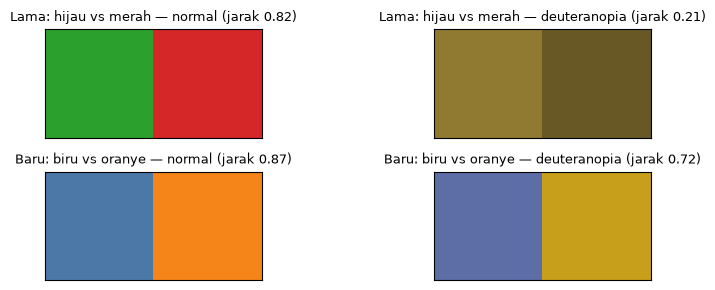

In [9]:
DEUTAN = np.array([[0.367, 0.861, -0.228], [0.280, 0.673, 0.047], [-0.012, 0.043, 0.969]])  # Machado et al. (2009), severity 1.0

def simulasi_deutan(hexwarna):
    rgb = np.clip(DEUTAN @ np.array(mcolors.to_rgb(hexwarna)), 0, 1)
    return mcolors.to_hex(rgb)

def jarak_warna(a, b):
    return np.linalg.norm(np.array(mcolors.to_rgb(a)) - np.array(mcolors.to_rgb(b)))

palet = {"Lama: hijau vs merah": ["#2CA02C", "#D62728"], "Baru: biru vs oranye": ["#4C78A8", "#F58518"]}
fig, ax = plt.subplots(2, 2, figsize=(9, 3))
for i, (nama, (a, b)) in enumerate(palet.items()):
    for j, (lbl, f) in enumerate([("normal", lambda x: x), ("deuteranopia", simulasi_deutan)]):
        ax[i, j].imshow([[mcolors.to_rgb(f(a)), mcolors.to_rgb(f(b))]]); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        ax[i, j].set_title(f"{nama} — {lbl} (jarak {jarak_warna(f(a), f(b)):.2f})", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Prototipe *high-fidelity*: dashboard interaktif (mantra Shneiderman)

1. **Overview first** — kartu KPI + tren total.
2. **Zoom & filter** — *range slider* tanggal, tombol pilih kabupaten.
3. **Details on demand** — angka rinci muncul saat kursor diarahkan (*hover*).

> Grafik Plotly interaktif tampil saat notebook dibuka di **Google Colab** (GitHub hanya menampilkan versi statis).

In [10]:
t0 = time.perf_counter()
bln_terakhir, bln_lalu = jual.bulan.max(), jual.bulan.max() - pd.DateOffset(months=1)
total_ini = jual.loc[jual.bulan == bln_terakhir, "penjualan_juta"].sum()
total_lalu = jual.loc[jual.bulan == bln_lalu, "penjualan_juta"].sum()

fig = go.Figure()
fig.add_trace(go.Indicator(mode="number+delta", value=total_ini / 1000, number={"suffix": " M", "valueformat": ".2f"},
                           delta={"reference": total_lalu / 1000, "relative": True, "valueformat": ".1%"},
                           title={"text": f"Penjualan {bln_terakhir:%b %Y} (miliar Rp)"},
                           domain={"x": [0, 0.3], "y": [0.75, 1]}))
turun = (bulanan.iloc[-1] / bulanan.iloc[-4] - 1).sort_values()
fig.add_trace(go.Indicator(mode="number", value=turun.iloc[0] * 100, number={"suffix": "%", "valueformat": ".0f",
                           "font": {"color": "#B22222"}}, title={"text": f"Penurunan terbesar 3 bln: {turun.index[0]}"},
                           domain={"x": [0.35, 0.65], "y": [0.75, 1]}))
fig.add_trace(go.Indicator(mode="number", value=jual.groupby(["kabupaten", "sektor"]).ngroups * 120,
                           title={"text": "UMKM aktif terpantau (sintetis)"}, domain={"x": [0.7, 1], "y": [0.75, 1]}))
for k in kab:
    fig.add_trace(go.Scatter(x=bulanan.index, y=bulanan[k], name=k, mode="lines",
                             line={"color": "#B22222" if k == "Seluma" else "#9E9E9E", "width": 3 if k == "Seluma" else 1.5},
                             hovertemplate="<b>%{fullData.name}</b><br>%{x|%b %Y}: Rp%{y:,.0f} juta<extra></extra>"))
tombol = [dict(label="Semua", method="update", args=[{"visible": [True] * (3 + len(kab))}])]
for k in kab:
    tombol.append(dict(label=k, method="update", args=[{"visible": [True] * 3 + [kk == k for kk in kab]}]))
fig.update_layout(height=600, template="simple_white", title="Dashboard Penjualan UMKM Provinsi Bengkulu (prototipe)",
                  yaxis={"domain": [0, 0.62], "title": "juta Rp / bulan"},
                  xaxis={"rangeslider": {"visible": True}, "rangeselector": {"buttons": [
                      dict(count=3, label="3 bln", step="month", stepmode="backward"),
                      dict(count=12, label="1 thn", step="month", stepmode="backward"), dict(step="all", label="semua")]}},
                  updatemenus=[dict(buttons=tombol, direction="down", x=1.0, xanchor="right", y=0.68)],
                  legend={"orientation": "h", "y": -0.45})
waktu_render = time.perf_counter() - t0
fig.write_html("dashboard_umkm.html", include_plotlyjs="cdn")
print(f"N1 — waktu membangun dashboard: {waktu_render:.2f} detik → {'LULUS' if waktu_render < 2 else 'GAGAL'} (< 2 detik)")
fig.show()

N1 — waktu membangun dashboard: 0.31 detik → LULUS (< 2 detik)


## 6. Evaluasi

### 6.1 Evaluasi heuristik (10 prinsip Nielsen) oleh 3 evaluator
Skala keparahan masalah: 0 = bukan masalah … 4 = katastrofik.

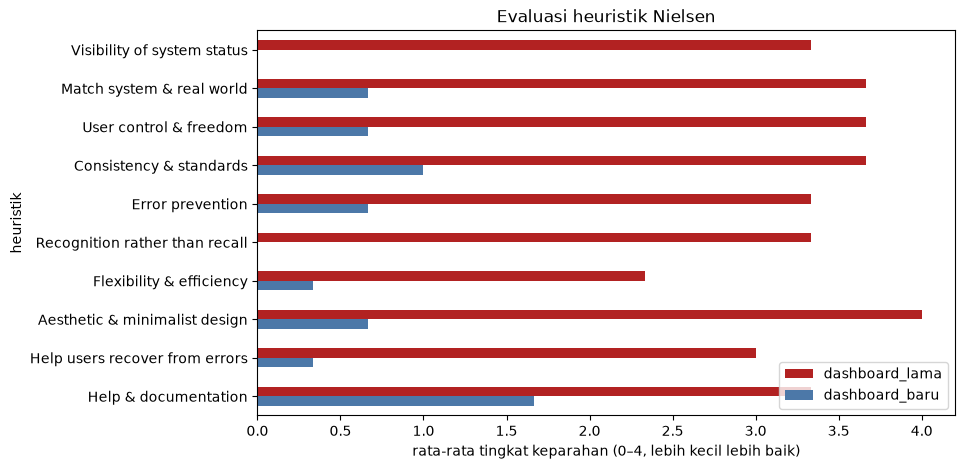

Masalah tersisa pada dashboard baru (keparahan ≥ 1,5): ['Help & documentation']


In [11]:
heuristik = ["Visibility of system status", "Match system & real world", "User control & freedom",
             "Consistency & standards", "Error prevention", "Recognition rather than recall",
             "Flexibility & efficiency", "Aesthetic & minimalist design", "Help users recover from errors",
             "Help & documentation"]
lama = rng.integers(2, 5, (3, 10)); lama[:, 7] = 4; lama[:, 0] = [3, 4, 3]
baru = rng.integers(0, 2, (3, 10)); baru[:, 9] = [2, 1, 2]
eval_h = pd.DataFrame({"heuristik": heuristik, "dashboard_lama": lama.mean(0), "dashboard_baru": baru.mean(0)})
ax = eval_h.set_index("heuristik").plot(kind="barh", figsize=(9, 5), color=["#B22222", "#4C78A8"])
ax.set_xlabel("rata-rata tingkat keparahan (0–4, lebih kecil lebih baik)"); ax.invert_yaxis()
ax.set_title("Evaluasi heuristik Nielsen"); plt.show()
print("Masalah tersisa pada dashboard baru (keparahan ≥ 1,5):",
      list(eval_h.loc[eval_h.dashboard_baru >= 1.5, "heuristik"]))

### 6.2 *Usability testing* — indikator objektif
12 responden (persona analis & staf dinas) mengerjakan 3 tugas pada kedua versi (urutan versi diacak):
T1 "temukan kabupaten yang penjualannya turun", T2 "berapa penjualan sektor kuliner Agustus 2026",
T3 "ekspor grafik tren Kota Bengkulu". Diukur: **keberhasilan tugas**, **waktu penyelesaian**, **jumlah kesalahan**,
dan kuesioner **SUS (System Usability Scale)**.

In [12]:
n_resp = 12
uji = []
for versi, p_sukses, mu_waktu, lam_err in [("lama", [0.55, 0.7, 0.6], [95, 70, 80], 2.2), ("baru", [0.95, 0.9, 0.92], [22, 35, 30], 0.5)]:
    for r in range(n_resp):
        for t in range(3):
            uji.append({"responden": r, "versi": versi, "tugas": f"T{t + 1}", "berhasil": rng.random() < p_sukses[t],
                        "waktu_detik": rng.lognormal(np.log(mu_waktu[t]), 0.35), "kesalahan": rng.poisson(lam_err)})
uji = pd.DataFrame(uji)
ringkas_uji = uji.groupby(["versi", "tugas"]).agg(tingkat_keberhasilan=("berhasil", "mean"),
                                                  median_waktu_detik=("waktu_detik", "median"),
                                                  rata_kesalahan=("kesalahan", "mean")).unstack("versi").round(2)
ringkas_uji

tingkat_keberhasilan       median_waktu_detik        rata_kesalahan  \
versi                 baru  lama               baru   lama           baru   
tugas                                                                       
T1                    1.00  0.33              22.59  88.69           0.58   
T2                    1.00  0.58              33.87  65.32           0.42   
T3                    0.92  0.58              30.82  85.95           0.58   

             
versi  lama  
tugas        
T1     2.25  
T2     2.67  
T3     1.75

In [13]:
# Uji statistik berpasangan (responden yang sama mencoba kedua versi)
w = uji.groupby(["responden", "versi"]).waktu_detik.mean().unstack()
t_stat, p_val = stats.wilcoxon(w["lama"], w["baru"])
print(f"Waktu rata-rata per tugas: lama {w['lama'].mean():.0f} s vs baru {w['baru'].mean():.0f} s "
      f"(Wilcoxon p = {p_val:.4f})")

Waktu rata-rata per tugas: lama 85 s vs baru 31 s (Wilcoxon p = 0.0005)


**System Usability Scale (SUS)** — 10 pernyataan skala 1–5. Item ganjil (positif): skor − 1; item genap (negatif):
5 − skor; jumlahkan lalu × 2,5 → 0–100. Skor ≥ 68 dianggap di atas rata-rata.

      lama  baru
mean  41.2  78.8
std    7.6   5.4
min   27.5  70.0
max   52.5  85.0


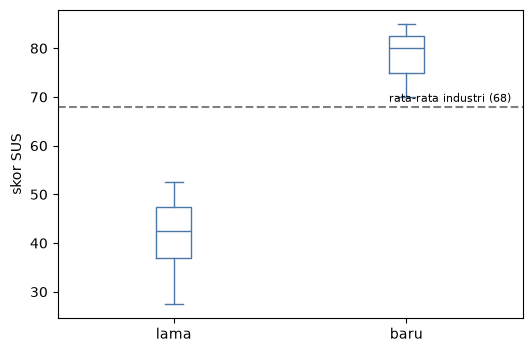

In [14]:
def skor_sus(jawaban):
    jawaban = np.asarray(jawaban)
    ganjil = jawaban[0::2] - 1
    genap = 5 - jawaban[1::2]
    return (ganjil.sum() + genap.sum()) * 2.5

def jawaban_acak(kecenderungan):
    pos = np.clip(np.round(rng.normal(kecenderungan, 0.7, 5)), 1, 5)
    neg = np.clip(np.round(rng.normal(6 - kecenderungan, 0.7, 5)), 1, 5)
    return np.ravel(np.column_stack([pos, neg]))

sus = pd.DataFrame({"lama": [skor_sus(jawaban_acak(2.6)) for _ in range(n_resp)],
                    "baru": [skor_sus(jawaban_acak(4.2)) for _ in range(n_resp)]})
print(sus.describe().loc[["mean", "std", "min", "max"]].round(1))
ax = sus.plot(kind="box", figsize=(6, 4), color="#4C78A8"); ax.axhline(68, ls="--", color="gray")
ax.text(2.45, 69, "rata-rata industri (68)", fontsize=8, ha="right"); ax.set_ylabel("skor SUS"); plt.show()

### 6.3 Verifikasi kebutuhan

In [15]:
kebutuhan["status"] = ["✔ kartu KPI", "✔ range slider & dropdown", "✔ hover template", "✔ HTML/PNG",
                       f"✔ {waktu_render:.2f} s", "✔ teks gelap & putih-di-merah lulus AA", "✔ palet biru–oranye/merah",
                       "✔ 3 KPI + 1 grafik utama"]
kebutuhan

,kode,jenis,kebutuhan,status
0,F1,Fungsional,"Menampilkan ringkasan KPI (total penjualan, pe...",✔ kartu KPI
1,F2,Fungsional,Filter rentang tanggal dan kabupaten/kota,✔ range slider & dropdown
2,F3,Fungsional,Detail angka muncul saat hover/klik (details o...,✔ hover template
3,F4,Fungsional,Ekspor grafik (PNG/HTML) untuk dibagikan,✔ HTML/PNG
4,N1,Non-fungsional,Waktu render grafik < 2 detik,✔ 0.31 s
5,N2,Non-fungsional,"Rasio kontras teks ≥ 4,5:1 (WCAG AA)",✔ teks gelap & putih-di-merah lulus AA
6,N3,Non-fungsional,Warna tetap dapat dibedakan oleh pengguna buta...,✔ palet biru–oranye/merah
7,N4,Non-fungsional,Maksimal 5–7 elemen informasi utama per layar ...,✔ 3 KPI + 1 grafik utama


## 7. Kesimpulan

* Desain dimulai dari **persona & skenario** (Budi, rapat mendadak), lalu diterjemahkan menjadi kebutuhan yang
  **dapat diuji** — termasuk kebutuhan non-fungsional seperti waktu render dan kontras.
* Perbaikan visual mengikuti teori kognitif: pie pelangi → batang terurut (mengurangi *extraneous load*),
  satu sorotan merah (atribut pre-atentif), *small multiples* (Gestalt), sumbu jujur (*lie factor* ≈ 1).
* Aksesibilitas diperiksa secara kuantitatif: rasio kontras WCAG dan simulasi deuteranopia.
* *Dashboard* interaktif menerapkan mantra **overview → zoom & filter → details on demand**.
* Keberhasilan dibuktikan dengan **indikator objektif** (menjawab pertanyaan peserta di sesi tanya-jawab): tingkat
  keberhasilan tugas, waktu, kesalahan, skor SUS, dan uji statistik — bukan sekadar "terlihat lebih bagus".

**Catatan:** data penjualan & hasil uji pengguna pada notebook ini disimulasikan. Pada proyek nyata, lakukan
wawancara/observasi pengguna (triangulasi), uji dengan 5–12 pengguna nyata, lalu ulangi siklus desain.